# 27 — What Does an RUL Number Have to Beat?

Notebook 16 reported that the two-channel state is worse than the clock it
contains over a whole trajectory — **132 minutes against 120** — and better only
after the alarm. It also stated, in prose, that predicting remaining life on
run-to-failure data is the same act as predicting total lifetime. Both claims
carry weight in the write-up, and neither was ever a table.

This builds the table, and adds the baseline notebook 16 noticed but never
scored. Its own caution was that both of its estimators were *"flattered by a
floor they get for free"* — a bearing that has run 54 minutes will live at least
54 minutes. If a free floor flatters an estimator, the floor belongs on the
scoreboard. Two go on it here: **`zero`**, which predicts no life remaining at
all, and **`survived`**, which predicts the unit will last twice as long as it
already has.

> *An error in minutes is not evidence until something degenerate has been asked
> to beat it.*

That is the demand notebook 22 made of attribution, where an exact permuted-label
null priced every accuracy this project reports. **RUL has never had a null.**
This is it.

Eight estimators, ordered by what they are allowed to know — `zero`, `survived`,
`med_all`, `med_cond`, `clock`, `state`, and `clock_post` / `state_post` refitted
on post-alarm rows only — scored on one leave-one-bearing-out pass over five
scopes. Built by `src/build_clock_table.py`.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = pathlib.Path("../data/processed")
d = pd.read_csv(OUT / "clock_table.csv")          # built by src/build_clock_table.py
ident = pd.read_csv(OUT / "clock_identity.csv")

ORD = ["zero", "survived", "med_all", "med_cond", "clock", "state",
       "clock_post", "state_post"]
LABEL = {"zero": "zero  (no life left)", "survived": "survived  (twice what it has run)",
         "med_all": "median lifetime", "med_cond": "median at this condition",
         "clock": "learned clock", "state": "two-channel state",
         "clock_post": "learned clock, post-alarm fit",
         "state_post": "two-channel state, post-alarm fit"}
d["fifth"] = np.clip((d["pos"] * 5).astype(int), 0, 4)

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})


def per_unit(mask, col="abs_err"):
    """Every scope in this notebook is a median over units, never over snapshots
    -- notebook 26 finding 4 showed pooling snapshots lets three long bearings
    carry 71 % of the weight."""
    return d[mask].groupby(["estimator", "unit"])[col].mean().reset_index()


print(f"{d['unit'].nunique()} units, {d['estimator'].nunique()} estimators, "
      f"{len(d):,} estimator-snapshots")

# Journal-resolution export of the manuscript figures (paper/figures/).
FIGDIR = pathlib.Path("../paper/figures")
FIGDIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Vector PDF, a 600-dpi RGB TIFF, and a greyscale proof for the print check.

    The TIFF is flattened onto white: an alpha channel leaves the background to
    whoever converts the file, and transparent can come back black.
    """
    from PIL import Image
    fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGDIR / f"{name}.tif", dpi=600, bbox_inches="tight",
                pil_kwargs={"compression": "tiff_lzw"})
    im = Image.open(FIGDIR / f"{name}.tif")
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        flat = Image.new("RGB", im.size, "white")
        flat.paste(im, mask=im.split()[-1])
        im = flat
    im.save(FIGDIR / f"{name}.tif", compression="tiff_lzw", dpi=(600, 600))
    proof = im.convert("L")
    proof.thumbnail((1600, 1600))
    (FIGDIR / "greyscale-proofs").mkdir(exist_ok=True)
    proof.save(FIGDIR / "greyscale-proofs" / f"{name}.png")
    print(f"  saved {name}: vector pdf, {im.size[0]}x{im.size[1]} RGB tif at 600 dpi, "
          f"greyscale proof")


15 units, 8 estimators, 73,728 estimator-snapshots


## Is an RUL number a lifetime number?

RUL = (L − 1) − t, and the minutes run *t* are known exactly. So any estimate of
remaining life implies an estimate of total life, L̂ = R̂UL + t + 1, and the two
errors must be the same number at every snapshot. Notebook 16 asserted it. Here
it is checked at all of them, for every estimator including the degenerate
ones.

In [2]:
# |RUL_hat - RUL| against |L_hat - L| at all 9216 snapshots x 8 estimators.
# The two are the same number in exact arithmetic; in float64 they are the same
# subtraction performed in a different order, so the residual should be bounded
# by the representation step at the magnitudes involved -- not asserted to be 0.
res = (d["abs_err"] - d["abs_err_life"]).abs()
ulp = np.spacing(d["life"].max())
print(f"largest residual over {len(d):,} estimator-snapshots : {res.max():.3e} minutes")
print(f"float64 step (1 ULP) at the longest life, {d['life'].max():.0f} min : {ulp:.3e}")
print(f"residual as a multiple of that step                 : {res.max() / ulp:.1f}")
print(f"largest residual relative to the error itself       : "
      f"{(res / d['abs_err'].clip(lower=1)).max():.2e}")
print()
print(f"estimator-unit pairs exactly zero : {int((ident['max_abs_diff'] == 0).sum())}"
      f" of {len(ident)}  (the closed-form estimators)")
print(f"the rest are forest fits, whose residual tracks lifetime magnitude:")
print(ident[ident["max_abs_diff"] > 0].groupby("estimator")["max_abs_diff"]
      .max().reindex([e for e in ORD if e in set(ident[ident['max_abs_diff'] > 0]['estimator'])])
      .to_string())
print()
chk = ident.groupby("estimator")[["mae_rul", "mae_life"]].mean().reindex(ORD)
chk["difference"] = chk["mae_rul"] - chk["mae_life"]
print(chk.round(12).to_string())

largest residual over 73,728 estimator-snapshots : 9.095e-13 minutes
float64 step (1 ULP) at the longest life, 2538 min : 4.547e-13
residual as a multiple of that step                 : 2.0
largest residual relative to the error itself       : 2.27e-13

estimator-unit pairs exactly zero : 63 of 120  (the closed-form estimators)
the rest are forest fits, whose residual tracks lifetime magnitude:
estimator
clock         2.273737e-13
state         4.547474e-13
clock_post    4.547474e-13
state_post    4.547474e-13

               mae_rul    mae_life  difference
estimator                                     
zero        306.700000  306.700000         0.0
survived    307.198974  307.198974         0.0
med_all     337.543658  337.543658         0.0
med_cond    465.763570  465.763570         0.0
clock       401.147358  401.147358         0.0
state       377.332439  377.332439         0.0
clock_post  280.240525  280.240525        -0.0
state_post  248.089431  248.089431         0.0


**The identity holds to the precision of the arithmetic.** The largest residual
over 73 728 estimator-snapshots is **9.1 × 10⁻¹³ minutes** — two units in the
last place of float64 at a 2 538-minute lifetime, where one ULP is
4.5 × 10⁻¹³. Relative to the errors themselves the residual is 2 × 10⁻¹³.

The 63 exactly-zero pairs are the closed-form estimators; the non-zero ones are
all forest fits, and their residual scales with lifetime magnitude, which is the
signature of representation noise rather than of a real difference. **The two
errors are the same subtraction written in a different order.** Notebook 16
reported this as "0.000000 minutes", which is true at six decimals; stated
precisely it is bounded by machine epsilon, and that is the stronger claim
because it is the one that survives recomputation.

This is not a property of the model. It is a property of the *benchmark*: on
run-to-failure data the elapsed time is known, so an RUL number and a
total-lifetime number are the same claim written two ways. A reported RUL error
is therefore a statement about how well total lifetime was guessed, and it
should be benchmarked against the things that guess lifetime without reading a
sensor at all.

Which is what the rest of this notebook does.

## The clock table

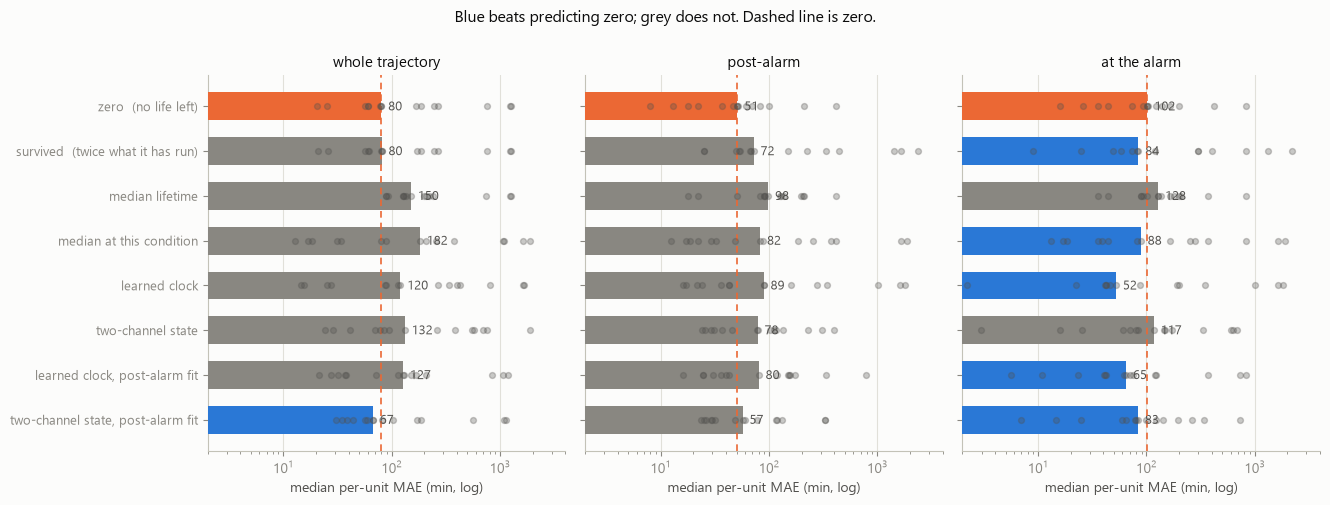

            whole trajectory  post-alarm  at the alarm
estimator                                             
zero                    80.0        51.0         102.0
survived                80.0        72.0          84.0
med_all                150.0        98.0         128.0
med_cond               182.0        82.0          88.0
clock                  120.0        89.0          52.0
state                  132.0        78.0         117.0
clock_post             127.0        80.0          65.0
state_post              67.0        57.0          83.0

whole trajectory : beats zero -> state_post
post-alarm       : beats zero -> nothing
at the alarm     : beats zero -> survived, med_cond, clock, clock_post, state_post


In [3]:
SCOPES = [("whole trajectory", d["post"].notna()), ("post-alarm", d["post"]),
          ("at the alarm", d["at_alarm"])]

tab = {}
for name, m in SCOPES:
    p = per_unit(m)
    tab[name] = p.groupby("estimator")["abs_err"].median().reindex(ORD)
T = pd.DataFrame(tab)

fig, axes = plt.subplots(1, 3, figsize=(13.4, 5.0), sharey=True)
y = np.arange(len(ORD))
for ax, (name, m) in zip(axes, SCOPES):
    v = T[name].to_numpy()
    zero_v = T.loc["zero", name]
    col = [C_ORANGE if k == "zero" else (C_BLUE if vv < zero_v else MUTED)
           for k, vv in zip(ORD, v)]
    ax.barh(y, v, height=0.62, color=col, zorder=3)
    ax.axvline(zero_v, color=C_ORANGE, lw=1.2, ls=(0, (4, 3)), zorder=4)
    for i, vv in enumerate(v):
        ax.annotate(f"{vv:.0f}", (vv, i), xytext=(5, -3), textcoords="offset points",
                    fontsize=9, color=INK2)
    pu = per_unit(m)
    for i, k in enumerate(ORD):                      # every unit, behind the median
        ax.scatter(pu.loc[pu["estimator"] == k, "abs_err"],
                   np.full((pu["estimator"] == k).sum(), i),
                   s=18, color=INK2, alpha=0.30, zorder=5)
    ax.set_xscale("log")
    ax.set_xlim(2, 4000)
    ax.grid(axis="y", visible=False)
    ax.set_title(name, fontsize=10.5)
    ax.set_xlabel("median per-unit MAE (min, log)")
axes[0].set_yticks(y, [LABEL[k] for k in ORD], fontsize=9.5)
axes[0].invert_yaxis()
fig.suptitle("Blue beats predicting zero; grey does not. Dashed line is zero.",
             fontsize=11.5, y=1.0)
plt.tight_layout()
plt.show()

print(T.round(0).to_string())
print()
for name, _ in SCOPES:
    w = [k for k in ORD if k != "zero" and T.loc[k, name] < T.loc["zero", name]]
    print(f"{name:17s}: beats zero -> {', '.join(w) if w else 'nothing'}")

**Over a whole trajectory only one estimator in the project beats predicting
zero, and after the alarm none does.**

`zero` — a model that says the bearing has no life left — scores a median
per-unit MAE of **80 minutes** over whole trajectories and **51** after the
alarm. Notebook 16's two-channel state scores 132 and 78. The learned clock
scores 120 and 89. Only the post-alarm-fit state (67 whole) clears the
degenerate baseline at all, and post-alarm even that loses, 57 against 51.

The one scope where real estimators win is **at the alarm**, where the learned
clock reaches 52 against zero's 102 — because at the moment of alarm a unit has
typically run long enough that "no life left" is a bad guess, while "about as
long as units like this usually run" is a good one.

Two readings, and the second matters more than the first.

The narrow one: notebook 16's ranking survives — the state beats the clock after
the alarm and loses before it — so nothing in that notebook is withdrawn.

The wide one: **MAE on RUL is not a scale on which a claim can be made.** A
degenerate constant wins it at two scopes out of three. Since the identity above
shows an RUL error *is* a lifetime error, and since lifetimes here span 60×, the
metric mostly reports how long the held-out bearing happened to live. The RUL
literature reports MAE and RMSE; on this benchmark those numbers are winnable
without a sensor.

## Does the gap close as failure approaches?

  saved fig5_remaining_life_vs_constant: vector pdf, 5453x3304 RGB tif at 600 dpi, greyscale proof


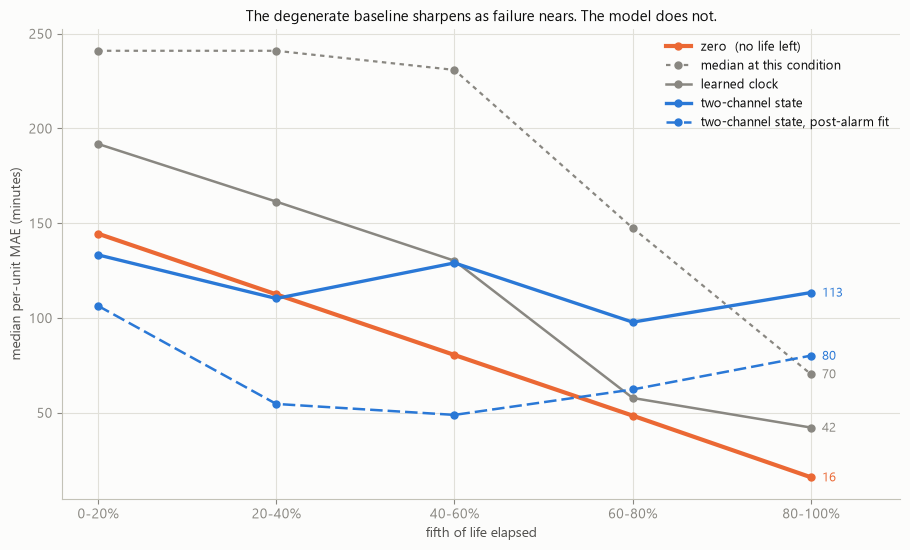

fifth           0      1      2      3      4
estimator                                    
zero        144.0  112.0   80.0   48.0   16.0
survived    129.0   65.0   16.0   63.0  128.0
med_all     198.0  198.0  184.0  136.0  127.0
med_cond    241.0  241.0  231.0  148.0   70.0
clock       192.0  161.0  130.0   58.0   42.0
state       133.0  110.0  129.0   98.0  113.0
clock_post  128.0  110.0   58.0   77.0   47.0
state_post  106.0   55.0   49.0   62.0   80.0

last fifth of life: zero 16 min vs state 113 min  ->  the model is 7.1x worse
zero falls 144 -> 16 min across the five fifths; state moves 133 -> 113


In [4]:
pf = d.groupby(["estimator", "fifth", "unit"])["abs_err"].mean().reset_index()
M = pf.groupby(["estimator", "fifth"])["abs_err"].median().unstack().reindex(ORD)

fig, ax = plt.subplots(figsize=(9.2, 5.6))
SHOW = ["zero", "med_cond", "clock", "state", "state_post"]
STY = {"zero": (C_ORANGE, 3.0, "-"), "state": (C_BLUE, 2.4, "-"),
       "state_post": (C_BLUE, 1.8, (0, (5, 2))), "clock": (MUTED, 1.8, "-"),
       "med_cond": (MUTED, 1.6, (0, (2, 2)))}
x = np.arange(5)
for k in SHOW:
    c, lw, ls = STY[k]
    ax.plot(x, M.loc[k], color=c, lw=lw, ls=ls, marker="o", ms=5, zorder=3,
            label=LABEL[k])
    ax.annotate(f"{M.loc[k].iloc[-1]:.0f}", (4, M.loc[k].iloc[-1]),
                xytext=(8, -3), textcoords="offset points", fontsize=9, color=c)
ax.set_xticks(x, ["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"])
ax.set_xlabel("fifth of life elapsed")
ax.set_ylabel("median per-unit MAE (minutes)")
ax.set_xlim(-0.2, 4.5)
ax.legend(fontsize=9, loc="upper right")
ax.set_title("The degenerate baseline sharpens as failure nears. The model does not.",
             fontsize=11)
plt.tight_layout()
save(fig, "fig5_remaining_life_vs_constant")
plt.show()

print(M.round(0).to_string())
print()
r = M.loc["state", 4] / M.loc["zero", 4]
print(f"last fifth of life: zero {M.loc['zero', 4]:.0f} min vs state "
      f"{M.loc['state', 4]:.0f} min  ->  the model is {r:.1f}x worse")
print(f"zero falls {M.loc['zero', 0]:.0f} -> {M.loc['zero', 4]:.0f} min across the five fifths; "
      f"state moves {M.loc['state', 0]:.0f} -> {M.loc['state', 4]:.0f}")

**This is notebook 16's flat error curve with a baseline underneath it, and the
baseline is what makes it damning.**

`zero` falls **144 → 112 → 80 → 48 → 16** minutes across the fifths, because a
bearing with less life left is easier to be right about by saying it has none.
That decline is the shape a prognostic is supposed to have. The two-channel
state moves **133 → 110 → 129 → 98 → 113** — flat, exactly as notebook 16 found.

In the **last fifth of life the model is 7.1× worse than predicting zero**, 113
minutes against 16. That is the window in which the maintenance decision is
actually taken.

Notebook 16 said the estimate is *"least informative exactly when the
maintenance decision must be taken"*. It now has a number, and the number is
worse than the prose suggested: the estimate is not merely flat while the target
shrinks, it is beaten several-fold by a constant.

## What survives on a scale that a constant cannot win

In [5]:
s = d[d["post"] & (d["y"] > 0)].copy()
s["rel"] = s["abs_err"] / s["y"]                  # error as a multiple of life left
rel = s.groupby(["estimator", "unit"])["rel"].median().groupby("estimator").median().reindex(ORD)

pu = per_unit(d["post"]).pivot(index="unit", columns="estimator", values="abs_err")
beats = pd.Series({k: int((pu[k] < pu["zero"]).sum()) for k in ORD if k != "zero"})

a = d[d["at_alarm"]]
opt = {k: ((a.loc[a["estimator"] == k, "pred"] > a.loc[a["estimator"] == k, "y"]).sum(),
           float((a.loc[a["estimator"] == k, "pred"] /
                  a.loc[a["estimator"] == k, "y"].clip(lower=1)).median()))
       for k in ORD}

summary = pd.DataFrame({
    "post-alarm MAE (min)": T["post-alarm"].round(0),
    "error / life left": rel.round(2),
    "beats zero (of 15)": pd.Series(beats).reindex(ORD),
    "optimistic at alarm": pd.Series({k: v[0] for k, v in opt.items()}).reindex(ORD),
    "x life remaining": pd.Series({k: v[1] for k, v in opt.items()}).reindex(ORD).round(2),
})
print(summary.to_string())
print()
print(f"scale-free, post-alarm: only {', '.join(rel[rel < 1.0].index.drop('zero', errors='ignore'))} "
      f"sit below 1.0 -- below the point where a constant zero is as good")
print(f"notebook 16 cross-check: state is optimistic on {opt['state'][0]}/15 units at the alarm, "
      f"median {opt['state'][1]:.2f}x the life that remained")

            post-alarm MAE (min)  error / life left  beats zero (of 15)  optimistic at alarm  x life remaining
zero                        51.0               1.00                 NaN                    0              0.00
survived                    72.0               1.40                 0.0                    6              0.71
med_all                     98.0               1.26                 2.0                    8              1.64
med_cond                    82.0               1.00                 7.0                    7              0.93
clock                       89.0               1.74                 7.0                   11              1.26
state                       78.0               1.26                 7.0                    9              1.73
clock_post                  80.0               0.97                 8.0                    7              0.92
state_post                  57.0               0.79                 8.0                    9              1.69



**On a scale-free measure the picture inverts, and that is the constructive
result.** Scored as error divided by the life actually left, `zero` is 1.00 by
construction. The two-channel state is **1.26** — still worse. But the
post-alarm-fit state reaches **0.79** and the post-alarm-fit clock **0.97**, so
*fitting on the rows where the question is live* is the one change that puts an
estimator genuinely ahead of a constant.

It is a thin lead. `state_post` beats zero on **8 of 15 units**, which is a coin
flip with an extra unit, and it is still optimistic at the alarm on 9 of 15 —
claiming a median **1.69×** the life that actually remained, against the 1.73×
notebook 16 reported for the whole-data fit.

This is why the project's RUL deliverable is a **floor** and not a number.
Notebooks 16, 17 and 26 never scored the floor on MAE; they scored it on the
**safety / give-up pair**, and the pair is exactly the scale a degenerate
estimator cannot win — `zero` is 100 % safe and gives up 100 % of the remaining
life, so it is visibly useless on the axis that matters. Notebook 26's `prior`
control was built on the same logic.

The pair was the right frame. This notebook shows what the alternative frame
would have cost.

### Findings

1. **An RUL error is a lifetime error, to within machine epsilon.** The largest
   residual across 73 728 estimator-snapshots is **9.1 × 10⁻¹³ minutes**, two
   ULP of float64 at the longest lifetime; 63 of 120 estimator-unit pairs are
   exactly zero and the rest are forest fits whose residual tracks lifetime
   magnitude. On run-to-failure data the two are one claim written two ways,
   because elapsed time is known.
2. **Notebook 16 reproduces exactly** — whole trajectory 132 (state) against 120
   (clock), post-alarm 78 against 89, post-alarm-fit 57 against 80 — so this
   harness is anchored to a published result before it is asked anything new.
3. **Predicting zero beats every estimator in the project after the alarm** (51
   min against the state's 78, the clock's 89, and the post-alarm-fit state's
   57), and all but one over whole trajectories (80 against 132, 120, and
   `state_post`'s 67).
4. **The only scope where a real estimator wins is at the alarm**, where the
   learned clock reaches 52 against zero's 102.
5. **The degenerate baseline sharpens and the model does not.** `zero` falls
   144 → 16 minutes across the fifths of life; the state moves 133 → 113. **In
   the last fifth the model is 7.1× worse than a constant.**
6. **On a scale-free measure only the post-alarm fits clear the constant** —
   error / life-left of 0.79 (`state_post`) and 0.97 (`clock_post`) against
   1.00 for zero and 1.26 for the state — and `state_post` beats zero on only
   **8 of 15 units**.
7. **Optimism survives the better fit.** At the alarm `state_post` is optimistic
   on 9 of 15 units at a median **1.69×** the life that remained, against 1.73×
   for the whole-data fit, so training where the question is live improves the
   error without fixing the direction.
8. **The safety / give-up pair is the frame that survives.** `zero` wins on MAE
   and is visibly worthless on the pair — 100 % safe, 100 % given up — which is
   what notebooks 16, 17 and 26 have been scoring the floor on all along.